# Portion 5 — Label efficiency, interpretability, robustness and failure analysis
**Inputs:** Portions 1–3 and Portion 4 v2 (falls back to Portion 4 v1). **Output:** `portion5_outputs/`.
**GPU:** recommended (sections 6–7 run the ViT encoders); a CPU runtime also works, just slower. Runtime on an A100 ≈ 5–10 min.

| Section | Question | Output |
|---|---|---|
| 4 Label efficiency | how many labelled frames does each frozen encoder need? (2–100 % of training frames, sampled as whole 30-s blocks) | Fig 5-1, `label_efficiency.csv` |
| 5 Encoder check | do the rebuilt encoders reproduce the Portion 3 embeddings exactly? (incl. the random-init B0) | printed check |
| 6 Interpretability | what does the proposed encoder look at? token-PCA, occlusion, integrated gradients + attribution statistics over many frames | Fig 5-2, 5-3, `attribution_stats.csv` |
| 7 Robustness | how much do scan-line streaks, noise, lower resolution, compressed contrast and drift change the read-out? | Fig 5-4, `robustness.csv` |
| 8 Failure analysis | where and why do held-out forecasts fail? | Fig 5-5, 5-6, `failure_cases.csv` |

Every figure is saved as vector PDF + 600-dpi PNG at journal widths; the arrays behind them go to `portion5_outputs/arrays/` for Portion 6.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports, device, journal style ---------------------------------------------------------------------
import os, json, time, math, warnings, logging, zlib
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import ndimage as ndi
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display
warnings.filterwarnings('ignore'); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
print('torch', torch.__version__, '| device', DEVICE, '| numpy', np.__version__, '| pandas', pd.__version__)

MM = 1 / 25.4; W1, W15, W2 = 89 * MM, 120 * MM, 183 * MM
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'] if f in _avail), 'DejaVu Sans')
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': [FONT], 'font.size': 7, 'axes.titlesize': 7.5,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.3,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5,
                     'ytick.major.size': 2.5, 'lines.linewidth': 1.1, 'lines.markersize': 3.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False, 'legend.frameon': False, 'figure.dpi': 150,
                     'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.titlelocation': 'left'})
def panel(ax, s, x=-0.16, y=1.04):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left')

torch 2.11.0+cu130 | device cuda | numpy 2.1.3 | pandas 2.2.3


In [3]:
# ---- 2. Configuration ------------------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P1_DIR, P2_DIR, P3_DIR = [os.path.join(DATA_DIR, f'portion{i}_outputs') for i in (1, 2, 3)]
P4_DIR = os.path.join(DATA_DIR, 'portion4_v2_outputs'); P4_V2 = os.path.exists(os.path.join(P4_DIR, 'metrics_all_v2.csv'))
if not P4_V2:
    P4_DIR = os.path.join(DATA_DIR, 'portion4_outputs')
OUT_DIR = os.path.join(DATA_DIR, 'portion5_outputs'); FIG = os.path.join(OUT_DIR, 'figures'); ARR = os.path.join(OUT_DIR, 'arrays')
for d in [OUT_DIR, FIG, ARR]:
    os.makedirs(d, exist_ok=True)
p3cfg = json.load(open(os.path.join(P3_DIR, 'run_config_portion3.json'))); C3 = p3cfg['config']; QUICK_P3 = bool(p3cfg.get('QUICK', False))
EMB_DIR = os.path.join(P3_DIR, C3.get('EMB_SUBDIR', 'embeddings')); RUNS_DIR = os.path.join(P3_DIR, 'runs')
print(f'Portion 4 {"v2" if P4_V2 else "v1"} | Portion-3 QUICK={QUICK_P3} | embeddings {EMB_DIR}')

LABEL_FRACTIONS = (0.02, 0.05, 0.10, 0.25, 0.50, 1.00)
LABEL_REPEATS, BLOCK_S = 5, 30.0
N_ATTR = 24                        # frames per held-out movie for the attribution statistics
IG_STEPS, OCC_PX = 16, 16
N_ROB = 96                         # frames per held-out movie for the robustness test
SEED = 0
if QUICK_P3 or os.environ.get('HSAFM_QUICK', '0') == '1':
    LABEL_REPEATS, N_ATTR, IG_STEPS, N_ROB = 2, 4, 4, 12

VCOL = {'B0': '#9a9a9a', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#2a78d6', 'B5': '#eda100'}
VNAME = {'B0': 'B0 random init', 'B2': 'B2 frame MAE', 'B3': 'B3 temporal MAE', 'B4': 'B4 temporal MAE + InfoNCE', 'B5': 'B5 shuffled time'}
conc_order = lambda c: float(str(c).replace('nM', ''))
def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(FIG, f'{name}.{ext}'), bbox_inches='tight')
    plt.show()

Portion 4 v2 | Portion-3 QUICK=False | embeddings /content/drive/MyDrive/Koushik-experiment/portion3_outputs/embeddings


In [4]:
# ---- 3. Shared data: labels and embeddings -----------------------------------------------------------------------
frames = pd.read_csv(os.path.join(P1_DIR, 'frames_all.csv'))
splits = json.load(open(os.path.join(P1_DIR, 'splits.json')))['splits']
idx = pd.read_csv(os.path.join(P3_DIR, 'dataset_index.csv'))
tg = pd.read_csv(os.path.join(P2_DIR, 'targets_per_frame.csv')).set_index('frame_id')
lab = idx.join(tg[['coverage', 'contrast_ok', 'fft_peak_ratio', 'density_um2', 'count_valid', 'regime']], on='frame_id')
streak = lab.frame_id.map(frames.set_index('frame_id').warn_streaks).fillna(False).astype(bool).values
lab.loc[streak, ['coverage', 'fft_peak_ratio', 'density_um2']] = np.nan
CONCS = sorted(lab.conc.unique(), key=conc_order)
CCOL = {c: plt.get_cmap('Blues')(0.38 + 0.54 * i / max(1, len(CONCS) - 1)) for i, c in enumerate(CONCS)}   # same ramp as Portion 6
loco = [s for s in splits if s.startswith('LOCO_') and os.path.isdir(os.path.join(EMB_DIR, s))]
VARIANTS = [v for v in ['B0', 'B2', 'B3', 'B4', 'B5'] if loco and os.path.exists(os.path.join(EMB_DIR, loco[0], f'{v}.npz'))]
PROBES = {'coverage': ('coverage', None, 'contrast_ok'), 'density (sparse)': ('density_um2', np.log1p, 'count_valid'),
          'lattice sharpness': ('fft_peak_ratio', np.log, None)}
def label_vec(name):
    col, fn, vm = PROBES[name]; y = lab[col].values.astype(float); ok = np.isfinite(y)
    if vm is not None: ok &= lab[vm].astype(bool).values
    if fn is not None: y = np.where(ok, fn(np.where(ok, y, 1.0)), np.nan)
    return y, ok
_EMB = {}
def get_emb(split, v):
    if (split, v) not in _EMB:
        d = np.load(os.path.join(EMB_DIR, split, f'{v}.npz'), allow_pickle=True)
        assert [str(x) for x in d['frame_id']] == [str(x) for x in idx.frame_id], 'embedding rows differ from dataset_index.csv'
        _EMB[(split, v)] = (d['Z'].astype(np.float32), [str(c) for c in d['train_concs']])
    return _EMB[(split, v)]
print('LOCO splits:', loco, '| variants:', VARIANTS, '| frames:', len(lab), '| streak frames without labels:', int(streak.sum()))

def ridge_fit(A, y, alpha):
    """closed-form ridge; dual form when n < d (fast with few labels). Returns (w, b, mean)."""
    m = A.mean(0); Ac = A - m; yc = y - y.mean(); n, d = Ac.shape
    if n < d:
        w = Ac.T @ np.linalg.solve(Ac @ Ac.T + alpha * np.eye(n), yc)
    else:
        w = np.linalg.solve(Ac.T @ Ac + alpha * np.eye(d), Ac.T @ yc)
    return w, y.mean(), m
ALPHAS = (1, 10, 100, 1000, 10000)
def choose_alpha(A, y, groups):
    """alpha by leave-one-concentration-out inside the training movies (one eigen-decomposition per inner fold)."""
    err = np.zeros(len(ALPHAS))
    for gg in np.unique(groups):
        tr = groups != gg
        if tr.sum() < 10 or (~tr).sum() < 3: continue
        Ac = A[tr] - A[tr].mean(0); yc = y[tr] - y[tr].mean(); ev, V = np.linalg.eigh(Ac.T @ Ac); r = V.T @ (Ac.T @ yc)
        for k, al in enumerate(ALPHAS):
            w = V @ (r / (ev + al)); err[k] += np.mean(np.abs((A[~tr] - A[tr].mean(0)) @ w + y[tr].mean() - y[~tr]))
    return ALPHAS[int(np.argmin(err))]

LOCO splits: ['LOCO_2nM', 'LOCO_4nM', 'LOCO_6nM', 'LOCO_8nM', 'LOCO_10nM'] | variants: ['B0', 'B2', 'B3', 'B4', 'B5'] | frames: 4036 | streak frames without labels: 87


1950 probe fits in 120s


,probe,variant,MAE_full,MAE_B0_full,fraction_to_match_B0_full
0,coverage,B0,0.1269,0.1269,0.50
1,coverage,B2,0.0799,0.1269,0.25
2,coverage,B3,0.0402,0.1269,0.10
3,coverage,B4,0.0557,0.1269,0.10
4,coverage,B5,0.0466,0.1269,0.05
5,density (sparse),B0,0.1139,0.1139,1.00
6,density (sparse),B2,0.2495,0.1139,NaN
7,density (sparse),B3,0.1795,0.1139,NaN
8,density (sparse),B4,0.2081,0.1139,NaN
9,density (sparse),B5,0.2177,0.1139,NaN


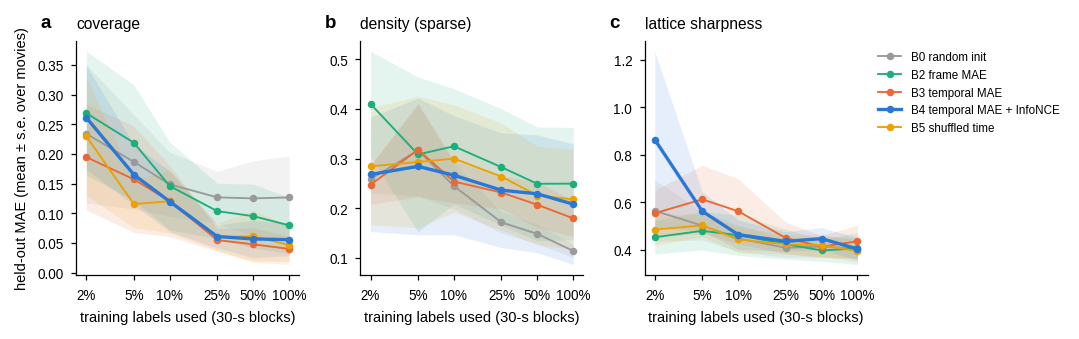

In [5]:
# ---- 4. Label efficiency of the frozen encoders (Fig 5-1) --------------------------------------------------------------
t0 = time.time(); rows = []
block_id = (lab.t_rel_s.values // BLOCK_S).astype(int)
for s in loco:
    tr_c, te_c = splits[s]['train'], splits[s]['test']
    for v in VARIANTS:
        Z, zc = get_emb(s, v); assert set(te_c).isdisjoint(zc), 'leakage'
        for pn in PROBES:
            y, ok = label_vec(pn)
            tr = ok & lab.conc.isin(tr_c).values; te = ok & lab.conc.isin(te_c).values
            if tr.sum() < 30 or te.sum() < 5: continue
            mu, sd = Z[tr].mean(0), Z[tr].std(0) + 1e-6; A = (Z - mu) / sd
            alpha = choose_alpha(A[tr], y[tr], lab.conc.values[tr])
            for f in LABEL_FRACTIONS:
                for rep in range(LABEL_REPEATS if f < 1 else 1):
                    rng = np.random.default_rng(SEED + 7919 * rep + int(f * 1000))
                    keep = np.zeros(len(lab), bool)
                    for c in tr_c:                                                # whole 30-s blocks of every training movie
                        mc = tr & (lab.conc.values == c); blocks = np.unique(block_id[mc])
                        if len(blocks) == 0: continue
                        keep |= mc & np.isin(block_id, rng.choice(blocks, max(1, int(round(f * len(blocks)))), replace=False))
                    if keep.sum() < 5: continue
                    w, b, m = ridge_fit(A[keep], y[keep], alpha)
                    rows.append(dict(split=s, test=te_c[0], variant=v, probe=pn, fraction=f, repeat=rep, n_labels=int(keep.sum()),
                                     MAE=float(np.mean(np.abs((A[te] - m) @ w + b - y[te])))))
LE = pd.DataFrame(rows); LE.to_csv(os.path.join(OUT_DIR, 'label_efficiency.csv'), index=False)
print(f'{len(LE)} probe fits in {time.time()-t0:.0f}s')
# labels needed: smallest fraction at which a variant matches random-init B0 trained on 100 % of the labels
need = []
for pn in PROBES:
    d = LE[LE.probe == pn].groupby(['variant', 'fraction']).MAE.mean().unstack('fraction')
    if 'B0' not in d.index: continue
    ref = d.loc['B0', 1.0]
    for v in d.index:
        hit = [f for f in d.columns if d.loc[v, f] <= ref]
        need.append(dict(probe=pn, variant=v, MAE_full=d.loc[v, 1.0], MAE_B0_full=ref, fraction_to_match_B0_full=min(hit) if hit else np.nan))
NEED = pd.DataFrame(need); NEED.to_csv(os.path.join(OUT_DIR, 'labels_needed.csv'), index=False); display(NEED.round(4))
if len(LE):
    fig, axes = plt.subplots(1, len(PROBES), figsize=(W2, 58 * MM), squeeze=False)
    for ax, pn, lt in zip(axes[0], PROBES, 'abc'):
        d = LE[LE.probe == pn]
        for v in VARIANTS:
            g = d[d.variant == v].groupby(['split', 'fraction']).MAE.mean().unstack('split')
            if g.empty: continue
            mu_, se = g.mean(1), g.std(1) / np.sqrt(max(1, g.shape[1]))
            ax.plot(g.index, mu_, marker='o', ms=2.6, color=VCOL[v], lw=1.6 if v == 'B4' else 0.9, label=VNAME[v], zorder=3 if v == 'B4' else 2)
            ax.fill_between(g.index, mu_ - se, mu_ + se, color=VCOL[v], alpha=0.12, lw=0)
        ax.set_xscale('log'); ax.set_xticks(LABEL_FRACTIONS); ax.set_xticklabels([f'{f*100:g}%' for f in LABEL_FRACTIONS])
        ax.minorticks_off(); ax.set_title(f'{pn}'); ax.set_xlabel('training labels used (30-s blocks)'); panel(ax, lt)
    axes[0, 0].set_ylabel('held-out MAE (mean ± s.e. over movies)')
    axes[0, -1].legend(fontsize=5.6, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout(); save(fig, 'fig5_1_label_efficiency')

In [6]:
# ---- 5. Rebuild the Portion 3 encoders (code copied verbatim) and verify against the saved embeddings ---------------------------
CROP, PATCH, TUBELET = int(C3['CROP']), int(C3['PATCH']), int(C3['TUBELET'])
ENC_DIM, ENC_DEPTH, ENC_HEADS = int(C3['ENC_DIM']), int(C3['ENC_DEPTH']), int(C3['ENC_HEADS'])
DEC_DIM, DEC_DEPTH, DEC_HEADS = int(C3['DEC_DIM']), int(C3['DEC_DEPTH']), int(C3['DEC_HEADS'])
T_FRAMES, TARGET_DT = int(C3['T_FRAMES']), float(C3['TARGET_DT'])
H_CLIP, H_SCALE, P3_SEED = float(C3.get('H_CLIP', 1.0)), float(C3.get('H_SCALE', 1.0)), int(C3.get('SEED', 0))

# --- verbatim copy of the Portion 3 model code (do not edit: B0 must be rebuilt bit-for-bit) ---
def sincos_1d(n, d):
    pos = np.arange(n, dtype=np.float64)[:, None]
    omega = 1.0 / 10000 ** (np.arange(d // 2, dtype=np.float64) / (d // 2))
    a = pos * omega[None]
    return np.concatenate([np.sin(a), np.cos(a)], axis=1)

def sincos_3d(t, h, w, dim):
    """separable 3-D sin-cos position embedding, (t*h*w, dim)."""
    dt_ = 2 * (dim // 6); dh = 2 * (dim // 6); dw = dim - dt_ - dh
    et, eh, ew = sincos_1d(t, dt_), sincos_1d(h, dh), sincos_1d(w, dw if dw % 2 == 0 else dw - 1)
    if dw % 2: ew = np.concatenate([ew, np.zeros((w, 1))], 1)
    e = np.concatenate([np.repeat(et, h * w, 0), np.tile(np.repeat(eh, w, 0), (t, 1)), np.tile(ew, (t * h, 1))], 1)
    return torch.tensor(e, dtype=torch.float32)

class Block(nn.Module):
    def __init__(self, dim, heads, mlp=4.0):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj, self.h = nn.Linear(dim, dim * 3), nn.Linear(dim, dim), heads
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp)), nn.GELU(), nn.Linear(int(dim * mlp), dim))
    def forward(self, x):
        B, N, C = x.shape
        q, k, v = self.qkv(self.n1(x)).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v)                      # Flash / memory-efficient attention when available
        x = x + self.proj(a.transpose(1, 2).reshape(B, N, C))
        return x + self.mlp(self.n2(x))

class VideoMAE(nn.Module):
    def __init__(self, T, tubelet, crop=CROP, patch=PATCH, dim=ENC_DIM, depth=ENC_DEPTH, heads=ENC_HEADS,
                 ddim=DEC_DIM, ddepth=DEC_DEPTH, dheads=DEC_HEADS, proj_dim=128):
        super().__init__()
        self.T, self.tt, self.p = T, tubelet, patch
        self.gt, self.gs = T // tubelet, crop // patch
        self.patch_embed = nn.Conv3d(1, dim, kernel_size=(tubelet, patch, patch), stride=(tubelet, patch, patch))
        self.register_buffer('pos', sincos_3d(self.gt, self.gs, self.gs, dim)[None], persistent=False)
        self.register_buffer('dpos', sincos_3d(self.gt, self.gs, self.gs, ddim)[None], persistent=False)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)]); self.norm = nn.LayerNorm(dim)
        self.dec_embed = nn.Linear(dim, ddim); self.mask_token = nn.Parameter(torch.zeros(1, 1, ddim))
        self.dblocks = nn.ModuleList([Block(ddim, dheads) for _ in range(ddepth)]); self.dnorm = nn.LayerNorm(ddim)
        self.head = nn.Linear(ddim, tubelet * patch * patch)
        self.proj = nn.Sequential(nn.Linear(dim, dim), nn.GELU(), nn.Linear(dim, proj_dim))
        nn.init.normal_(self.mask_token, std=0.02); self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def patchify(self, x):                     # (B,1,T,H,W) -> (B, N, tt*p*p) in token order (t, h, w)
        B = x.shape[0]; tt, p, gt, gs = self.tt, self.p, self.gt, self.gs
        x = x.reshape(B, gt, tt, gs, p, gs, p).permute(0, 1, 3, 5, 2, 4, 6)
        return x.reshape(B, gt * gs * gs, tt * p * p)

    def unpatchify(self, y):
        B = y.shape[0]; tt, p, gt, gs = self.tt, self.p, self.gt, self.gs
        y = y.reshape(B, gt, gs, gs, tt, p, p).permute(0, 1, 4, 2, 5, 3, 6)
        return y.reshape(B, 1, gt * tt, gs * p, gs * p)

    def make_mask(self, B, ratio, tube, gen_t):
        S, N = self.gs * self.gs, self.gt * self.gs * self.gs
        if tube:                                # same spatial positions hidden in every temporal slice
            keep_s = max(1, int(round(S * (1 - ratio))))
            noise = torch.rand(B, S, device=self.pos.device, generator=gen_t)
            ids_s = noise.argsort(1)[:, :keep_s]
            ids_keep = (ids_s[:, None, :] + S * torch.arange(self.gt, device=ids_s.device)[None, :, None]).reshape(B, -1)
        else:
            keep = max(1, int(round(N * (1 - ratio))))
            ids_keep = torch.rand(B, N, device=self.pos.device, generator=gen_t).argsort(1)[:, :keep]
        mask = torch.ones(B, N, device=ids_keep.device); mask.scatter_(1, ids_keep, 0.0)
        return ids_keep.sort(1).values, mask

    def encode(self, x, ids_keep=None):
        tok = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos
        if ids_keep is not None:
            tok = torch.gather(tok, 1, ids_keep[..., None].expand(-1, -1, tok.shape[-1]))
        for b in self.blocks:
            tok = b(tok)
        return self.norm(tok)

    def forward_mae(self, x, ratio, tube, gen_t):
        B = x.shape[0]
        ids_keep, mask = self.make_mask(B, ratio, tube, gen_t)
        lat = self.encode(x, ids_keep)
        d = self.dec_embed(lat); N = mask.shape[1]
        full = self.mask_token.expand(B, N, -1).clone().to(d.dtype)
        full.scatter_(1, ids_keep[..., None].expand(-1, -1, d.shape[-1]), d)
        full = full + self.dpos
        for b in self.dblocks:
            full = b(full)
        pred = self.head(self.dnorm(full))
        tgt = self.patchify(x)
        mu, var = tgt.mean(-1, keepdim=True), tgt.var(-1, keepdim=True)
        tgt_n = (tgt - mu) / (var + 1e-6).sqrt()                          # per-patch normalised target
        loss = (((pred.float() - tgt_n) ** 2).mean(-1) * mask).sum() / mask.sum()
        return loss, lat, pred, mask, (mu, var)

    @torch.no_grad()
    def embed(self, x):
        """frozen representation: [mean over all tokens, mean over the most recent tubelet]."""
        tok = self.encode(x)
        S = self.gs * self.gs
        return torch.cat([tok.mean(1), tok[:, -S:].mean(1)], dim=1)

def make_model(variant):
    return VideoMAE(T=1, tubelet=1) if variant == 'B2' else VideoMAE(T=T_FRAMES, tubelet=TUBELET)

def load_model(split, variant):
    if variant == 'B0':                                            # identical recipe to Portion 3: reseed, then build
        torch.manual_seed(P3_SEED); return make_model('B4').to(DEVICE).eval()
    m = make_model(variant).to(DEVICE)
    st = torch.load(os.path.join(RUNS_DIR, f'{split}__{variant}', 'final.pt'), map_location=DEVICE, weights_only=False)
    m.load_state_dict(st['model']); return m.eval()

def embed_grad(m, x):
    """same representation as VideoMAE.embed but differentiable (for integrated gradients)."""
    tok = m.encode(x); S = m.gs * m.gs
    return torch.cat([tok.mean(1), tok[:, -S:].mean(1)], dim=1)

X_np = np.load(os.path.join(P3_DIR, 'dataset_5nm_f16.npy'), mmap_mode='r'); H0, W0 = X_np.shape[1:]
kept = idx.copy(); kept['pos'] = kept.groupby('session').cumcount()
dts = kept.groupby('session').t_rel_s.apply(lambda s: float(np.median(np.diff(s.values))) if len(s) > 1 else TARGET_DT)
kept['stride'] = kept.session.map(lambda s: max(1, int(round(TARGET_DT / max(dts[s], 1e-3)))))
sess_start = kept.index.values - kept.pos.values
OY, OX = (H0 - CROP) // 2, (W0 - CROP) // 2                     # the centre crop used in Portion 3
def clip_nm(g, T):
    """(T, CROP, CROP) nm heights of the causal clip ending at frame g (Portion 3 rule)."""
    rows = sess_start[g] + np.clip(kept.pos.values[g] - kept.stride.values[g] * np.arange(T - 1, -1, -1), 0, None)
    return np.asarray(X_np[rows][:, OY:OY + CROP, OX:OX + CROP], np.float32)
def to_in(a):
    return (np.clip(a, -1.0, 4.0) - H_CLIP) / H_SCALE
def embed_batch(m, clips_nm):
    x = torch.as_tensor(to_in(clips_nm)[:, None], device=DEVICE)
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        return embed_grad(m, x).float().cpu().numpy()

chk = []
s0 = loco[len(loco) // 2] if loco else None
for v in [x for x in ['B0', 'B4', 'B2'] if x in VARIANTS]:
    m = load_model(s0, v); T_ = 1 if v == 'B2' else T_FRAMES
    gs_ = np.linspace(0, len(kept) - 1, 8).astype(int)
    z_new = embed_batch(m, np.stack([clip_nm(g, T_) for g in gs_])); z_old = get_emb(s0, v)[0][gs_]
    r = np.corrcoef(z_new.ravel(), z_old.ravel())[0, 1]; rel = np.abs(z_new - z_old).max() / (np.abs(z_old).max() + 1e-9)
    chk.append(dict(split=s0, variant=v, correlation=float(r), max_rel_diff=float(rel), ok=bool(r > 0.995))); del m
CHK = pd.DataFrame(chk); display(CHK.round(5))
assert CHK.ok.all(), 'rebuilt encoders do not reproduce the Portion 3 embeddings - check that portion3_outputs is complete'

,split,variant,correlation,max_rel_diff,ok
0,LOCO_6nM,B0,1.0,0.0,True
1,LOCO_6nM,B4,1.0,0.0,True
2,LOCO_6nM,B2,1.0,0.0,True


B4 encoder of LOCO_6nM, held-out 6nM: example frames [1483, 1506, 1942]


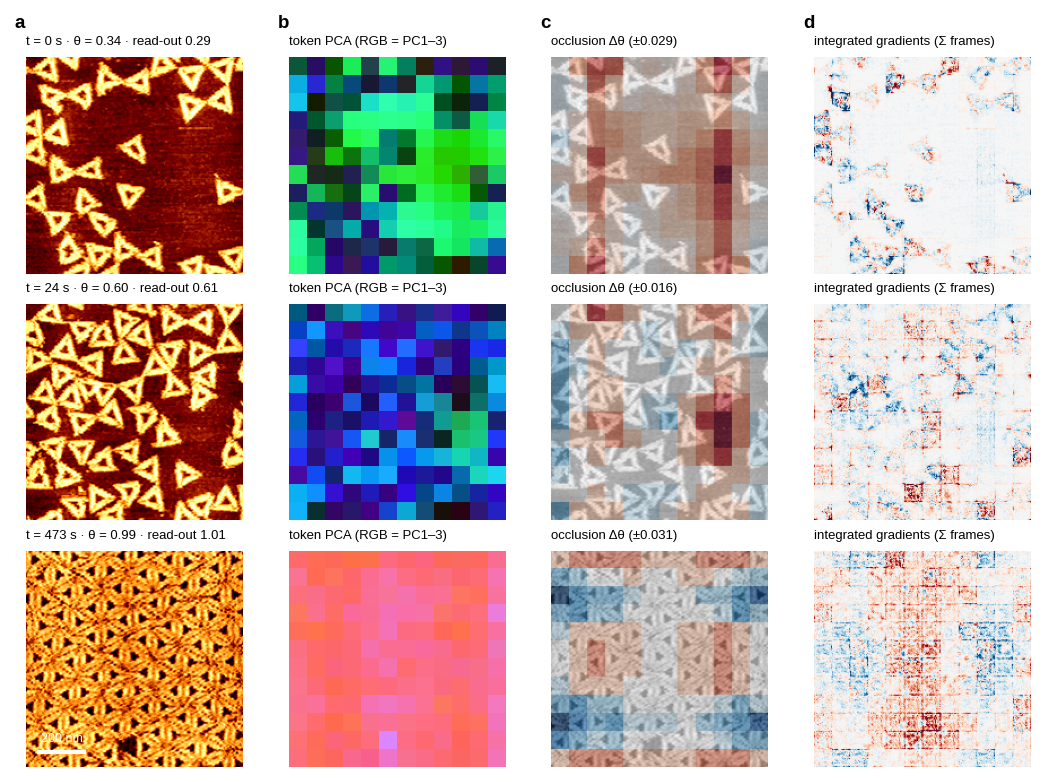

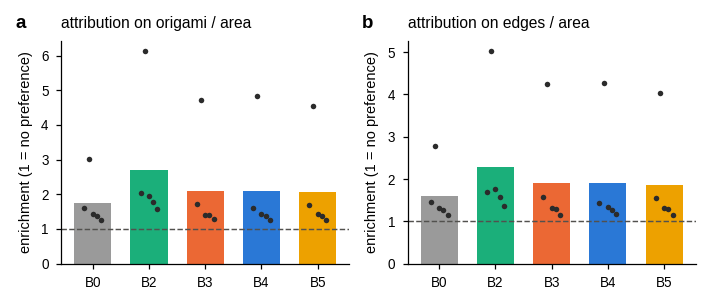

,enrich_origami,enrich_edges,ratio_origami_vs_mica
variant,,,
B0,1.736,1.592,2.492
B2,2.685,2.280,7.522
B3,2.104,1.916,3.477
B4,2.103,1.898,3.408
B5,2.057,1.865,3.280


In [7]:
# ---- 6. Interpretability: coverage read-out of the proposed encoder (Fig 5-2, 5-3) ---------------------------------------------------
def coverage_probe(s, v):
    """ridge read-out of coverage trained on the TRAINING movies of split s; returns torch callable on embeddings."""
    Z, _ = get_emb(s, v); y, ok = label_vec('coverage'); trm = ok & lab.conc.isin(splits[s]['train']).values
    zmu, zsd = Z[trm].mean(0), Z[trm].std(0) + 1e-6; A = (Z - zmu) / zsd
    w, b, m = ridge_fit(A[trm], y[trm], choose_alpha(A[trm], y[trm], lab.conc.values[trm]))
    wt = torch.tensor(w / zsd, dtype=torch.float32, device=DEVICE); bt = float(b - (m * w).sum() - ((zmu / zsd) * w).sum())
    return (lambda z: z.float() @ wt + bt), (lambda Zn: ((Zn - zmu) / zsd - m) @ w + b)

def frame_threshold(h):
    return float(np.clip(0.4 * np.percentile(h, 99), 0.3, 0.8))   # Portion 2 adaptive mica/origami threshold

def ig_batch(m, probe_t, clips_nm, steps=IG_STEPS):
    """integrated gradients (baseline = bare-mica clip), summed over time -> (n, CROP, CROP)."""
    out = []
    for c in clips_nm:
        x = torch.as_tensor(to_in(c)[None, None], device=DEVICE); base = torch.full_like(x, (0.0 - H_CLIP) / H_SCALE)
        al = torch.linspace(1.0 / steps, 1.0, steps, device=DEVICE).view(-1, 1, 1, 1, 1)
        xi = (base + al * (x - base)).detach().requires_grad_(True)
        g, = torch.autograd.grad(probe_t(embed_grad(m, xi)).sum(), xi)
        out.append(((x - base) * g.mean(0, keepdim=True))[0, 0].sum(0).detach().cpu().numpy())
    return np.stack(out)

def occlusion(m, probe_t, clip, px=OCC_PX, chunk=48):
    x = torch.as_tensor(to_in(clip)[None, None], device=DEVICE)
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        p0 = float(probe_t(embed_grad(m, x))[0])
        pos = [(y, x_) for y in range(0, CROP - px + 1, px) for x_ in range(0, CROP - px + 1, px)]; d = []
        for k in range(0, len(pos), chunk):
            b = x.repeat(len(pos[k:k + chunk]), 1, 1, 1, 1).clone()
            for j, (y, x_) in enumerate(pos[k:k + chunk]):
                b[j, ..., y:y + px, x_:x_ + px] = (0.0 - H_CLIP) / H_SCALE
            d.append(probe_t(embed_grad(m, b)).float().cpu().numpy() - p0)
    n = CROP // px
    return np.concatenate(d).reshape(n, n), p0

show_split = 'LOCO_6nM' if 'LOCO_6nM' in loco else loco[len(loco) // 2]
show_v = 'B4' if 'B4' in VARIANTS else [v for v in VARIANTS if v != 'B0'][-1]
test_c = splits[show_split]['test'][0]
y_cov, ok_cov = label_vec('coverage')
cand = lab[(lab.conc == test_c) & ok_cov]
ex = list(dict.fromkeys(int((cand.coverage - t).abs().idxmin()) for t in (0.15, 0.6, 0.995))) if len(cand) else []
assert ex, f'no frames with measured coverage in the held-out {test_c} movie'
m4 = load_model(show_split, show_v); probe_t, probe_np = coverage_probe(show_split, show_v)
clips = np.stack([clip_nm(g, T_FRAMES) for g in ex])
IG = ig_batch(m4, probe_t, clips)
OCC, P0 = zip(*[occlusion(m4, probe_t, c) for c in clips])
with torch.no_grad():
    tok = m4.encode(torch.as_tensor(to_in(clips)[:, None], device=DEVICE)).float()[:, -m4.gs * m4.gs:].cpu().numpy()
allt = tok.reshape(-1, tok.shape[-1]); mu_t = allt.mean(0); _, _, Vt = np.linalg.svd(allt - mu_t, full_matrices=False)
RGB = ((tok - mu_t) @ Vt[:3].T).reshape(len(ex), m4.gs, m4.gs, 3)
lo_, hi_ = np.percentile(RGB.reshape(-1, 3), [2, 98], axis=0); RGB = np.clip((RGB - lo_) / (hi_ - lo_ + 1e-9), 0, 1)
np.savez_compressed(os.path.join(ARR, 'interpretability_examples.npz'), frames=clips[:, -1], ig=IG, occ=np.stack(OCC), rgb=RGB,
                    pred=np.array(P0), measured=lab.coverage.values[ex], t=lab.t_rel_s.values[ex], conc=test_c, variant=show_v, split=show_split,
                    patch_nm=PATCH * 5.0, occ_px=OCC_PX)
print(f'{show_v} encoder of {show_split}, held-out {test_c}: example frames {ex}')

fig, axes = plt.subplots(len(ex), 4, figsize=(W2, 44 * MM * len(ex)), squeeze=False)
for i, g in enumerate(ex):
    fr = clips[i, -1]
    axes[i, 0].imshow(fr, cmap='afmhot', vmin=-0.5, vmax=2.5); axes[i, 0].set_title(f't = {lab.t_rel_s[g]:.0f} s · θ = {lab.coverage[g]:.2f} · read-out {P0[i]:.2f}', fontsize=6.3)
    axes[i, 1].imshow(RGB[i], interpolation='nearest'); axes[i, 1].set_title('token PCA (RGB = PC1–3)', fontsize=6.3)
    lim = np.abs(OCC[i]).max() + 1e-9
    axes[i, 2].imshow(fr, cmap='gray', vmin=-0.5, vmax=2.5)
    axes[i, 2].imshow(np.kron(OCC[i], np.ones((OCC_PX, OCC_PX))), cmap='RdBu_r', vmin=-lim, vmax=lim, alpha=0.6)
    axes[i, 2].set_title(f'occlusion Δθ (±{lim:.3f})', fontsize=6.3)
    lim2 = np.percentile(np.abs(IG[i]), 99.5) + 1e-9
    axes[i, 3].imshow(IG[i], cmap='RdBu_r', vmin=-lim2, vmax=lim2); axes[i, 3].set_title('integrated gradients (Σ frames)', fontsize=6.3)
    for a in axes[i]: a.axis('off')
    if i == 0:
        for a, lt in zip(axes[0], 'abcd'): panel(a, lt, x=-0.05, y=1.12)
axes[-1, 0].plot([0.06 * CROP, 0.06 * CROP + 40], [0.93 * CROP] * 2, color='white', lw=2); axes[-1, 0].text(0.06 * CROP + 20, 0.89 * CROP, '200 nm', color='white', ha='center', va='bottom', fontsize=6)
fig.tight_layout(w_pad=0.3, h_pad=0.6); save(fig, 'fig5_2_interpretability_examples')

# attribution statistics over many held-out frames, every LOCO split and every pretrained variant
attr_rows = []; rng = np.random.default_rng(SEED)
for s in loco:
    te_c = splits[s]['test'][0]; pool = np.where(ok_cov & (lab.conc.values == te_c) & (lab.coverage.values > 0.05) & (lab.coverage.values < 0.95))[0]
    if len(pool) == 0: continue
    pick = np.sort(rng.choice(pool, min(N_ATTR, len(pool)), replace=False))
    for v in [x for x in VARIANTS if x != 'B0'] + (['B0'] if 'B0' in VARIANTS else []):
        m = load_model(s, v); pt, _ = coverage_probe(s, v); T_ = 1 if v == 'B2' else T_FRAMES
        cl = np.stack([clip_nm(g, T_) for g in pick]); ig = np.abs(ig_batch(m, pt, cl))
        for j, g in enumerate(pick):
            fr = cl[j, -1]; ori = fr > frame_threshold(fr); edge = ori ^ ndi.binary_erosion(ori, iterations=2)
            if not (0.03 < ori.mean() < 0.97): continue
            a = ig[j]; tot = a.sum() + 1e-12
            attr_rows.append(dict(split=s, test=te_c, variant=v, frame=int(g), coverage=float(lab.coverage[g]), origami_area=float(ori.mean()),
                                  attr_on_origami=float(a[ori].sum() / tot), attr_on_edges=float(a[edge].sum() / tot), edge_area=float(edge.mean()),
                                  ratio_origami_vs_mica=float(a[ori].mean() / (a[~ori].mean() + 1e-12))))
        del m
ATTR = pd.DataFrame(attr_rows); ATTR.to_csv(os.path.join(OUT_DIR, 'attribution_stats.csv'), index=False)
if len(ATTR):
    ATTR['enrich_origami'] = ATTR.attr_on_origami / ATTR.origami_area; ATTR['enrich_edges'] = ATTR.attr_on_edges / ATTR.edge_area.clip(lower=1e-6)
    vv = [v for v in VARIANTS if v in ATTR.variant.unique()]
    fig, axes = plt.subplots(1, 2, figsize=(W15, 52 * MM))
    for ax, col, ttl, lt in zip(axes, ['enrich_origami', 'enrich_edges'], ['attribution on origami / area', 'attribution on edges / area'], 'ab'):
        for j, v in enumerate(vv):
            d = ATTR[ATTR.variant == v].groupby('split')[col].mean()
            ax.bar(j, d.mean(), color=VCOL[v], width=0.66)
            ax.scatter(np.full(len(d), j) + np.linspace(-0.15, 0.15, len(d)), d, s=7, color='#2b2b2b', zorder=3, lw=0)
        ax.axhline(1, color='#52514e', ls='--', lw=0.7); ax.set_xticks(range(len(vv))); ax.set_xticklabels(vv)
        ax.set_title(ttl); ax.set_ylabel('enrichment (1 = no preference)'); panel(ax, lt)
    fig.tight_layout(); save(fig, 'fig5_3_attribution_statistics')
    display(ATTR.groupby('variant')[['enrich_origami', 'enrich_edges', 'ratio_origami_vs_mica']].mean().round(3))

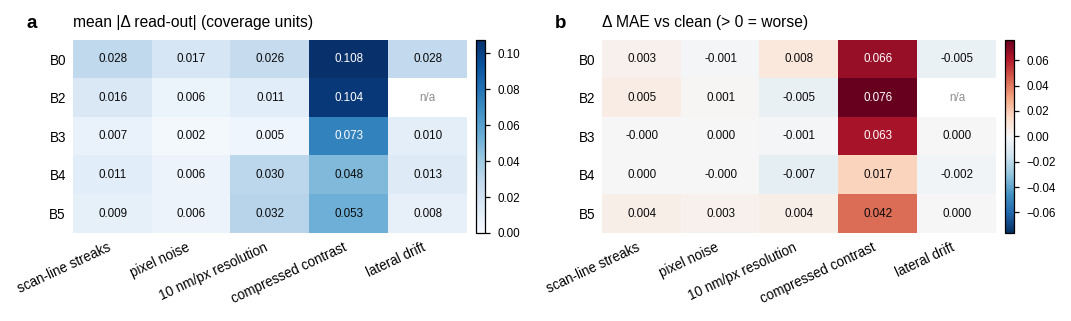

perturbation,scan-line streaks,pixel noise,10 nm/px resolution,compressed contrast,lateral drift
variant,,,,,
B0,0.0282,0.0169,0.0261,0.1076,0.0280
B2,0.0155,0.0059,0.0114,0.1042,NaN
B3,0.0074,0.0023,0.0045,0.0734,0.0103
B4,0.0114,0.0060,0.0301,0.0481,0.0132
B5,0.0092,0.0059,0.0318,0.0532,0.0085


perturbation,scan-line streaks,pixel noise,10 nm/px resolution,compressed contrast,lateral drift
variant,,,,,
B0,0.0031,-0.0012,0.0081,0.0664,-0.0053
B2,0.0055,0.0010,-0.0054,0.0762,NaN
B3,-0.0004,0.0001,-0.0007,0.0626,0.0002
B4,0.0004,-0.0000,-0.0067,0.0168,-0.0023
B5,0.0043,0.0030,0.0043,0.0423,0.0003


In [8]:
# ---- 7. Robustness to imaging perturbations (Fig 5-4) ----------------------------------------------------------------------------
def perturb(cl, kind, rng):
    cl = cl.copy()
    if kind == 'scan-line streaks':
        hit = rng.random(cl.shape[:2] + (cl.shape[2],)) < 0.10
        cl += (hit * rng.normal(0, 0.5, hit.shape))[..., None]
    elif kind == 'pixel noise':
        cl += rng.normal(0, 0.15, cl.shape)
    elif kind == '10 nm/px resolution':
        n, T, h, w = cl.shape; c2 = cl[:, :, :h // 2 * 2, :w // 2 * 2].reshape(n, T, h // 2, 2, w // 2, 2).mean((3, 5))
        cl[:, :, :h // 2 * 2, :w // 2 * 2] = np.repeat(np.repeat(c2, 2, 2), 2, 3)
    elif kind == 'compressed contrast':
        cl *= 0.7
    elif kind == 'lateral drift':
        for t in range(cl.shape[1]):
            cl[:, t] = np.roll(cl[:, t], shift=(t, t), axis=(1, 2))
    return cl.astype(np.float32)
PERTS = ['scan-line streaks', 'pixel noise', '10 nm/px resolution', 'compressed contrast', 'lateral drift']
rob = []
for s in loco:
    te_c = splits[s]['test'][0]; pool = np.where(ok_cov & (lab.conc.values == te_c))[0]
    if len(pool) == 0: continue
    pick = np.sort(np.random.default_rng(SEED + 1).choice(pool, min(N_ROB, len(pool)), replace=False))
    for v in VARIANTS:
        m = load_model(s, v); _, pnp = coverage_probe(s, v); T_ = 1 if v == 'B2' else T_FRAMES
        cl = np.stack([clip_nm(g, T_) for g in pick]); z0 = embed_batch(m, cl); p0 = pnp(z0); yt = y_cov[pick]
        for kind in PERTS:
            rng_ = np.random.default_rng(zlib.crc32((s + v + kind).encode()))
            p1 = pnp(np.concatenate([embed_batch(m, perturb(cl[k:k + 32], kind, rng_)) for k in range(0, len(cl), 32)]))
            na = (kind == 'lateral drift' and T_ == 1)                     # a single-frame encoder cannot see drift
            rob.append(dict(split=s, test=te_c, variant=v, perturbation=kind, n=len(pick), mean_abs_shift=np.nan if na else float(np.mean(np.abs(p1 - p0))),
                            MAE_clean=float(np.mean(np.abs(p0 - yt))), MAE_perturbed=np.nan if na else float(np.mean(np.abs(p1 - yt)))))
        del m
ROB = pd.DataFrame(rob); ROB.to_csv(os.path.join(OUT_DIR, 'robustness.csv'), index=False)
if len(ROB):
    ROB['delta_MAE'] = ROB.MAE_perturbed - ROB.MAE_clean
    H = ROB.groupby(['variant', 'perturbation']).mean_abs_shift.mean().unstack('perturbation').reindex(index=VARIANTS, columns=PERTS)
    D = ROB.groupby(['variant', 'perturbation']).delta_MAE.mean().unstack('perturbation').reindex(index=VARIANTS, columns=PERTS)
    fig, axes = plt.subplots(1, 2, figsize=(W2, 55 * MM))
    for ax, M_, ttl, cmap, lt in [(axes[0], H, 'mean |Δ read-out| (coverage units)', 'Blues', 'a'),
                                  (axes[1], D, 'Δ MAE vs clean (> 0 = worse)', 'RdBu_r', 'b')]:
        vals = M_.values.astype(float)
        if cmap == 'RdBu_r':
            l_ = max(1e-3, np.nanmax(np.abs(vals))); im = ax.imshow(vals, cmap=cmap, norm=TwoSlopeNorm(vcenter=0, vmin=-l_, vmax=l_), aspect='auto')
        else:
            im = ax.imshow(vals, cmap=cmap, vmin=0, aspect='auto')
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                if np.isfinite(vals[i, j]):
                    ax.text(j, i, f'{vals[i, j]:.3f}', ha='center', va='center', fontsize=5.6,
                            color='white' if abs(vals[i, j]) > 0.6 * np.nanmax(np.abs(vals)) else '#0b0b0b')
                else:
                    ax.text(j, i, 'n/a', ha='center', va='center', fontsize=5.6, color='#8f8f8f')
        ax.set_xticks(range(len(PERTS))); ax.set_xticklabels(PERTS, rotation=25, ha='right'); ax.set_yticks(range(len(VARIANTS)))
        ax.set_yticklabels(VARIANTS); ax.set_title(ttl); ax.tick_params(length=0); panel(ax, lt, x=-0.12)
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        cbar = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cbar.ax.tick_params(labelsize=5.6)
    fig.tight_layout(); save(fig, 'fig5_4_robustness')
    display(H.round(4)); display(D.round(4))

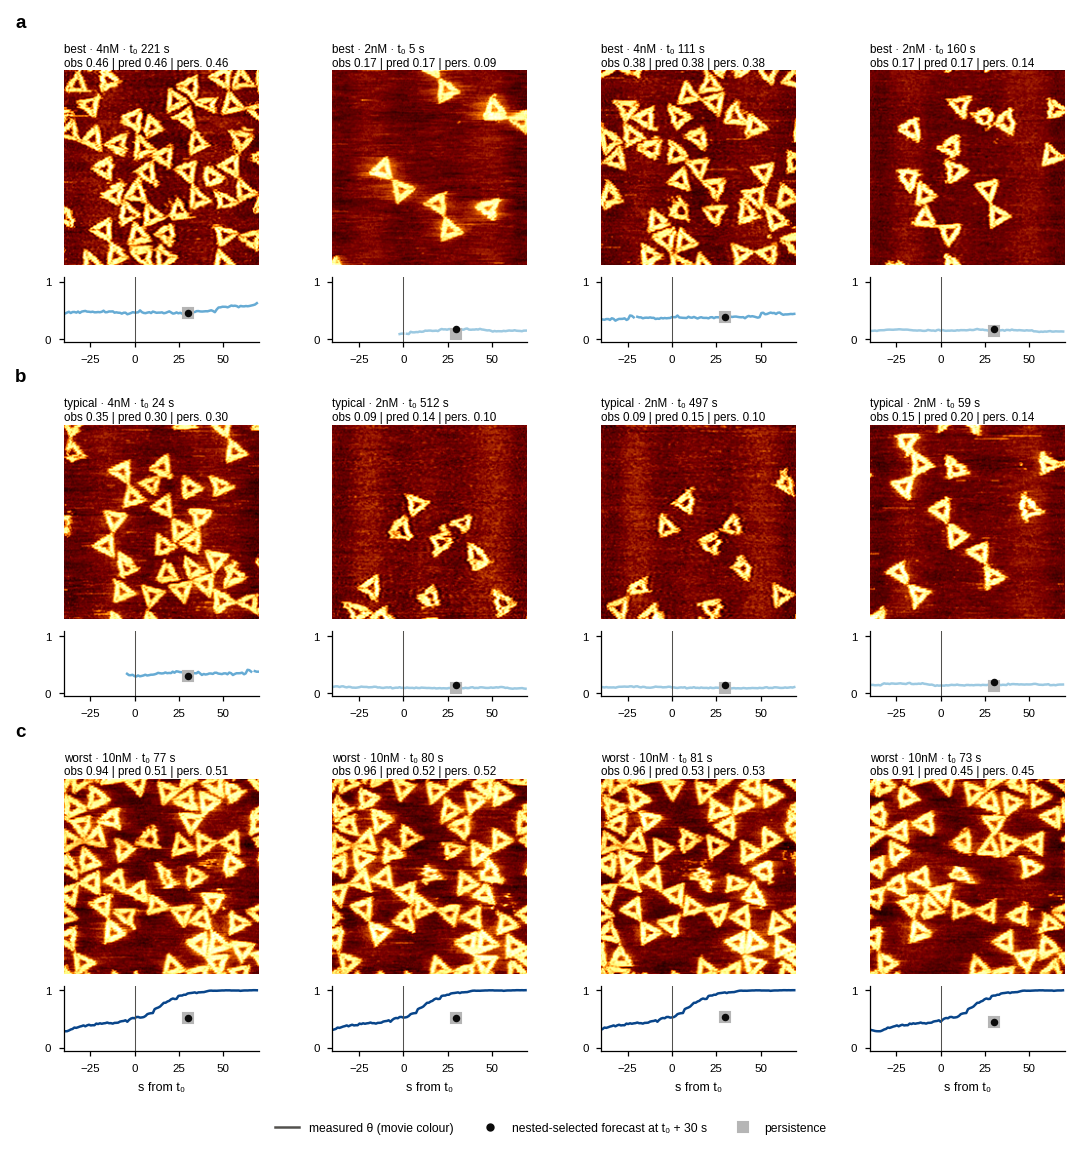

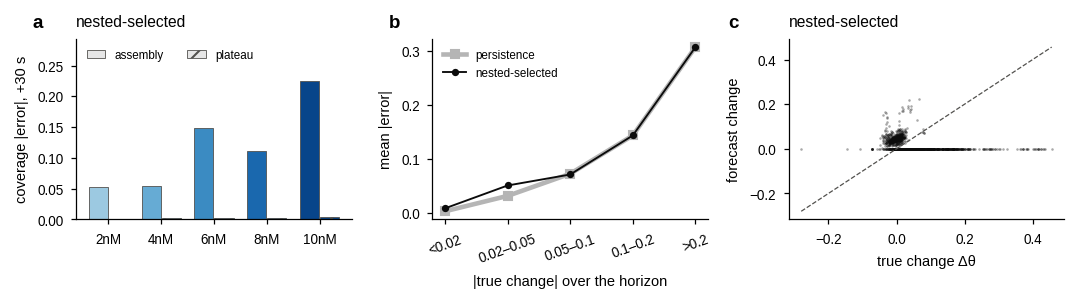

err         err_persistence        
phase assembly plateau        assembly plateau
conc                                          
10nM    0.2256  0.0034          0.2256  0.0034
2nM     0.0526     NaN          0.0140     NaN
4nM     0.0541  0.0027          0.0541  0.0027
6nM     0.1487  0.0023          0.1487  0.0023
8nM     0.1106  0.0027          0.1106  0.0027

In [9]:
# ---- 8. Failure analysis of held-out forecasts (Fig 5-5, 5-6) -------------------------------------------------------------------------
MET = pd.read_csv(os.path.join(P4_DIR, 'metrics_all_v2.csv' if P4_V2 else 'metrics_all.csv'))
P4_MODELS = list(dict.fromkeys(MET.model))
GAL = 'nested-selected' if 'nested-selected' in P4_MODELS else ('B4+phys' if 'B4+phys' in P4_MODELS else P4_MODELS[-1])
p4cfg = json.load(open(os.path.join(P4_DIR, 'run_config_portion4_v2.json' if P4_V2 else 'run_config_portion4.json')))
HORIZONS = tuple(p4cfg['config']['HORIZONS']); PH = 30.0 if 30.0 in HORIZONS else HORIZONS[len(HORIZONS) // 2]; hp = HORIZONS.index(PH)
T_ABS = lab.t_rel_s.values; Ycov = lab.coverage.values
cases = []
for s in loco:
    f = os.path.join(P4_DIR, 'predictions', f'{s}.npz')
    if not os.path.exists(f): continue
    R = np.load(f, allow_pickle=True); te_rows = R['te_rows']; P = R[GAL].mean(0)[:, hp, 0]; Pp = R['persistence'].mean(0)[:, hp, 0]
    c = splits[s]['test'][0]; rr = np.where(lab.conc.values == c)[0]; tt = T_ABS[rr]
    for i, g in enumerate(te_rows):
        j = int(np.argmin(np.abs(tt - (T_ABS[g] + PH))))
        if abs(tt[j] - (T_ABS[g] + PH)) > 3 or not np.isfinite(Ycov[rr[j]]) or not np.isfinite(Ycov[g]): continue
        cases.append(dict(split=s, conc=c, row=int(g), t0=float(T_ABS[g]), now=float(Ycov[g]), obs=float(Ycov[rr[j]]),
                          pred=float(P[i]), persistence=float(Pp[i]), regime=str(lab.regime[g])))
CA = pd.DataFrame(cases)
if len(CA):
    CA['err'] = (CA.pred - CA.obs).abs(); CA['err_persistence'] = (CA.persistence - CA.obs).abs(); CA['change'] = CA.obs - CA.now
    CA['phase'] = np.where(CA.now < 0.95, 'assembly', 'plateau')
    CA['change_bin'] = pd.cut(CA.change.abs(), [-1e-9, 0.02, 0.05, 0.1, 0.2, 1.01], labels=['<0.02', '0.02–0.05', '0.05–0.1', '0.1–0.2', '>0.2'])
    CA.to_csv(os.path.join(OUT_DIR, 'failure_cases.csv'), index=False)
    act = CA[CA.phase == 'assembly'].sort_values('err').reset_index(drop=True)
    if len(act) >= 12:
        mid = len(act) // 2
        pick = pd.concat([act.iloc[:4].assign(kind='best'), act.iloc[mid - 2:mid + 2].assign(kind='typical'), act.iloc[-4:].assign(kind='worst')])
        pick.to_csv(os.path.join(OUT_DIR, 'gallery_cases.csv'), index=False)
        FW_, FH_, IMG_, PITCH_, ROW_ = 183.0, 190.0, 33.0, 45.5, 60.0
        fig = plt.figure(figsize=(FW_ * MM, FH_ * MM))
        Ax = lambda x, y, w, h: fig.add_axes([x / FW_, 1 - (y + h) / FH_, w / FW_, h / FH_])   # millimetres from top-left
        for k, (_, r) in enumerate(pick.iterrows()):
            rr_, cc = divmod(k, 4); x0, y0 = 9 + cc * PITCH_, 8 + rr_ * ROW_
            ax = Ax(x0, y0, IMG_, IMG_); ax.imshow(np.asarray(X_np[int(r.row)], np.float32), cmap='afmhot', vmin=-0.5, vmax=2.5); ax.axis('off')
            ax.set_title(f'{r.kind} · {r.conc} · t₀ {r.t0:.0f} s\nobs {r.obs:.2f} | pred {r.pred:.2f} | pers. {r.persistence:.2f}', fontsize=5.6, pad=2, loc='left')
            if cc == 0: panel(ax, 'abc'[rr_], x=-0.25, y=1.2)
            ax2 = Ax(x0, y0 + IMG_ + 2.0, IMG_, 11.0); rr = np.where(lab.conc.values == r.conc)[0]; w_ = (T_ABS[rr] > r.t0 - 40) & (T_ABS[rr] < r.t0 + 70)
            ax2.plot(T_ABS[rr][w_] - r.t0, Ycov[rr][w_], color=CCOL.get(r.conc, 'k'), lw=1.2)
            ax2.plot([PH], [r.persistence], 's', color='#b5b5b5', ms=4.5); ax2.plot([PH], [r.pred], 'o', color='#0b0b0b', ms=2.6)
            ax2.axvline(0, color='#52514e', lw=0.5); ax2.set_ylim(-0.05, 1.08); ax2.set_xlim(-40, 70); ax2.set_yticks([0, 1]); ax2.tick_params(labelsize=5.5)
            if rr_ == 2: ax2.set_xlabel('s from t₀', fontsize=6)
        fig.legend(handles=[Line2D([], [], color='#52514e', lw=1.2, label='measured θ (movie colour)'),
                            Line2D([], [], marker='o', ls='none', color='#0b0b0b', ms=3, label=f'{GAL} forecast at t₀ + {PH:.0f} s'),
                            Line2D([], [], marker='s', ls='none', color='#b5b5b5', ms=4.5, label='persistence')],
                   loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=5.8, frameon=False)
        save(fig, 'fig5_5_forecast_gallery')
    # where do errors come from?
    fig, axes = plt.subplots(1, 3, figsize=(W2, 52 * MM))
    g1 = CA.groupby(['conc', 'phase'])[['err', 'err_persistence']].mean().unstack('phase')
    cs = [c for c in CONCS if c in g1.index]; xx = np.arange(len(cs))
    for j, (ph, hatch) in enumerate([('assembly', None), ('plateau', '///')]):
        if ('err', ph) in g1.columns:
            axes[0].bar(xx + (j - 0.5) * 0.38, g1.loc[cs, ('err', ph)], width=0.36, color=[CCOL[c] for c in cs], hatch=hatch, edgecolor='#52514e', lw=0.4)
    axes[0].set_xticks(xx); axes[0].set_xticklabels(cs); axes[0].set_ylabel(f'coverage |error|, +{PH:.0f} s'); axes[0].set_title(GAL)
    axes[0].set_ylim(0, max(1e-3, np.nanmax(g1['err'].values)) * 1.3)
    axes[0].legend(handles=[Patch(fc='#e6e6e6', ec='#52514e', lw=0.4, label='assembly'), Patch(fc='#e6e6e6', ec='#52514e', lw=0.4, hatch='///', label='plateau')],
                   fontsize=5.6, loc='upper left', ncol=2, handlelength=1.6); panel(axes[0], 'a')
    g2 = CA.groupby('change_bin', observed=False)[['err', 'err_persistence']].mean()
    axes[1].plot(range(len(g2)), g2.err_persistence, '-s', color='#b5b5b5', lw=2.2, ms=4, label='persistence')
    axes[1].plot(range(len(g2)), g2.err, '-o', color='#0b0b0b', lw=0.9, ms=2.5, label=GAL)
    axes[1].set_xticks(range(len(g2))); axes[1].set_xticklabels(g2.index.astype(str), rotation=20); axes[1].set_xlabel('|true change| over the horizon')
    axes[1].set_ylabel('mean |error|'); axes[1].legend(fontsize=5.6); panel(axes[1], 'b')
    axes[2].scatter(CA.change, CA.pred - CA.now, s=1.5, alpha=0.35, color='#0b0b0b', lw=0)
    l_ = [min(CA.change.min(), (CA.pred - CA.now).min()), max(CA.change.max(), (CA.pred - CA.now).max())]
    axes[2].plot(l_, l_, ls='--', color='#52514e', lw=0.6); axes[2].set_xlabel('true change Δθ'); axes[2].set_ylabel('forecast change'); axes[2].set_title(GAL); panel(axes[2], 'c', x=-0.22)
    fig.tight_layout(); save(fig, 'fig5_6_error_anatomy')
    display(g1.round(4))

In [10]:
# ---- 9. Summary --------------------------------------------------------------------------------------------------------------------------
summ = []
if len(LE):
    full = LE[LE.fraction == 1.0].groupby(['probe', 'variant']).MAE.mean().unstack('variant')
    summ.append(('Best frozen encoder per probe (100 % labels)', '; '.join(f'{p}: {full.loc[p].idxmin()} ({full.loc[p].min():.4f})' for p in full.index)))
if len(NEED):
    for _, r in NEED[NEED.variant == 'B4'].iterrows():
        summ.append((f'B4 labels needed to match B0@100 % ({r.probe})', 'not reached' if np.isnan(r.fraction_to_match_B0_full) else f'{r.fraction_to_match_B0_full*100:g} %'))
if len(ATTR):
    a_ = ATTR.groupby('variant')[['enrich_origami', 'enrich_edges']].mean()
    summ.append(('Attribution enrichment on origami / edges', '; '.join(f'{v}: {a_.loc[v, "enrich_origami"]:.2f} / {a_.loc[v, "enrich_edges"]:.2f}' for v in a_.index)))
if len(ROB):
    worst = ROB.groupby('perturbation').mean_abs_shift.mean().idxmax()
    summ.append(('Most damaging perturbation (mean over encoders)', worst))
    summ.append(('Read-out shift under streaks', '; '.join(f'{v}: {x:.4f}' for v, x in ROB[ROB.perturbation == 'scan-line streaks'].groupby('variant').mean_abs_shift.mean().items())))
if len(CA):
    summ.append((f'{GAL} vs persistence |error|, assembly / plateau',
                 f'{CA[CA.phase=="assembly"].err.mean():.4f} vs {CA[CA.phase=="assembly"].err_persistence.mean():.4f} / '
                 f'{CA[CA.phase=="plateau"].err.mean():.4f} vs {CA[CA.phase=="plateau"].err_persistence.mean():.4f}'))
SUM = pd.DataFrame(summ, columns=['finding', 'value']); display(SUM); SUM.to_csv(os.path.join(OUT_DIR, 'summary_portion5.csv'), index=False)
json.dump(dict(created=datetime.now().isoformat(timespec='seconds'), device=str(DEVICE), torch=torch.__version__, portion4=('v2' if P4_V2 else 'v1'),
               portion3_quick=QUICK_P3, font=FONT, config={k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool, tuple))}),
          open(os.path.join(OUT_DIR, 'run_config_portion5.json'), 'w'), indent=1, default=str)
if QUICK_P3:
    print('Portion 3 ran in QUICK mode, so these numbers only prove the pipeline works.')
print('Outputs:', sorted(os.listdir(OUT_DIR)))

,finding,value
0,Best frozen encoder per probe (100 % labels),coverage: B3 (0.0402); density (sparse): B0 (0...
1,B4 labels needed to match B0@100 % (coverage),10 %
2,B4 labels needed to match B0@100 % (density (s...,not reached
3,B4 labels needed to match B0@100 % (lattice sh...,100 %
4,Attribution enrichment on origami / edges,B0: 1.74 / 1.59; B2: 2.69 / 2.28; B3: 2.10 / 1...
5,Most damaging perturbation (mean over encoders),compressed contrast
6,Read-out shift under streaks,B0: 0.0282; B2: 0.0155; B3: 0.0074; B4: 0.0114...
7,"nested-selected vs persistence |error|, assemb...",0.0776 vs 0.0599 / 0.0028 vs 0.0028


Outputs: ['arrays', 'attribution_stats.csv', 'failure_cases.csv', 'figures', 'gallery_cases.csv', 'label_efficiency.csv', 'labels_needed.csv', 'robustness.csv', 'run_config_portion5.json', 'summary_portion5.csv']


## Outputs (`portion5_outputs/`)
| File | Content |
|---|---|
| `label_efficiency.csv`, `labels_needed.csv` | held-out probe MAE vs fraction of training labels; fraction each encoder needs to match random-init with all labels |
| `attribution_stats.csv` | integrated-gradient enrichment on origami and on origami edges, per frame, split and encoder |
| `robustness.csv` | read-out shift and MAE change under 5 imaging perturbations, per split and encoder |
| `failure_cases.csv`, `gallery_cases.csv` | every held-out forecast with its error, phase and true change |
| `arrays/interpretability_examples.npz` | frames, IG, occlusion and token-PCA arrays (re-plotted by Portion 6) |
| `figures/fig5_*.pdf/.png` | vector PDF + 600-dpi PNG |